In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_bc_final_seeds as eval_bc

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [4]:
rl_root = "/home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv"

bc_dir = os.path.join(rl_root, "bc_with_logprobs", "split_0", "sepsis", "combined_hourly_iv-vasoactive_inotropic_score", 
                      "with_actions", "five_seeds")
bc_study = R.make_study(bc_dir, family="bc", group_by=(), name="bc")
bc_models = M.load_study_models(bc_study)[()]

  loaded LoadedModel(bc seed 0: actor)
  loaded LoadedModel(bc seed 1: actor)
  loaded LoadedModel(bc seed 2: actor)
  loaded LoadedModel(bc seed 3: actor)
  loaded LoadedModel(bc seed 4: actor)


# Load data

In [5]:
store = D.DataStore(keep=("train", "val"))
procs = {s: store.processor(m, "val") for s, m in bc_models.items()}      # each seed on ITS OWN states
train_ref = store.reference("train")                                      # shared train split: actions, severity edges

print({s: m.record.data_identity.short() for s, m in bc_models.items()})
display(D.check_rows_aligned(procs))

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: train, val)
usin

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,174053,True,True,True,True,True
1,174053,True,True,True,True,False
2,174053,True,True,True,True,False
3,174053,True,True,True,True,False
4,174053,True,True,True,True,False


# evaluate

In [9]:
eval_bc.check_loglik_matches(bc_models, procs)

  seed 0: gate_smooth=0.02; mean shift of the behaviour log-lik from smoothing -0.1151 nats/hour
  seed 0: max |difference| over 5000 rows = 5.64e-06
  seed 1: gate_smooth=0.02; mean shift of the behaviour log-lik from smoothing -0.1204 nats/hour
  seed 1: max |difference| over 5000 rows = 1.01e-05
  seed 2: gate_smooth=0.02; mean shift of the behaviour log-lik from smoothing -0.1164 nats/hour
  seed 2: max |difference| over 5000 rows = 5.07e-06
  seed 3: gate_smooth=0.02; mean shift of the behaviour log-lik from smoothing -0.1164 nats/hour
  seed 3: max |difference| over 5000 rows = 4.80e-06
  seed 4: gate_smooth=0.02; mean shift of the behaviour log-lik from smoothing -0.1202 nats/hour
  seed 4: max |difference| over 5000 rows = 7.22e-06


In [10]:
ref = eval_bc.marginal_reference(train_ref)
display(eval_bc.loglik_table(bc_models, procs, ref).round(3))

fired_share  gate_ll_bc  gate_ll_base  mag_ll_bc  mag_ll_base  \
seed drug                                                                   
0    fluid        0.724      -0.275        -0.590      0.938        0.726   
     vaso         0.196      -0.188        -0.497      0.792        0.554   
1    fluid        0.724      -0.260        -0.590      0.913        0.726   
     vaso         0.196      -0.172        -0.497      0.789        0.554   
2    fluid        0.724      -0.279        -0.590      0.919        0.726   
     vaso         0.196      -0.177        -0.497      0.787        0.554   
3    fluid        0.724      -0.272        -0.590      0.915        0.726   
     vaso         0.196      -0.180        -0.497      0.775        0.554   
4    fluid        0.724      -0.253        -0.590      0.910        0.726   
     vaso         0.196      -0.175        -0.497      0.815        0.554   

            gain_per_row  
seed drug                 
0    fluid         0.469  
     vaso          0.356  
1    fluid         0.465  
     vaso          0.371  
2    fluid         0.451  
     vaso          0.365  
3    fluid         0.455  
     vaso          0.361  
4    fluid         0.471  
     vaso          0.373

obs_rate  mean_pred  p_at_zero_mean  p_at_zero_over_half  \
seed drug                                                              
0    fluid     0.724      0.643           0.105                0.072   
     vaso      0.196      0.193           0.068                0.026   
1    fluid     0.724      0.652           0.102                0.072   
     vaso      0.196      0.202           0.067                0.029   
2    fluid     0.724      0.645           0.110                0.076   
     vaso      0.196      0.200           0.069                0.027   
3    fluid     0.724      0.654           0.119                0.084   
     vaso      0.196      0.198           0.069                0.026   
4    fluid     0.724      0.657           0.105                0.073   
     vaso      0.196      0.198           0.066                0.027   

            p_at_given_mean  brier    ece  auroc  
seed drug                                         
0    fluid            0.848  0.082  0.081  0.965  
     vaso             0.704  0.054  0.020  0.965  
1    fluid            0.862  0.076  0.072  0.967  
     vaso             0.757  0.049  0.015  0.970  
2    fluid            0.849  0.083  0.079  0.963  
     vaso             0.736  0.050  0.015  0.968  
3    fluid            0.858  0.080  0.070  0.961  
     vaso             0.728  0.051  0.016  0.967  
4    fluid            0.867  0.074  0.067  0.967  
     vaso             0.739  0.050  0.016  0.969

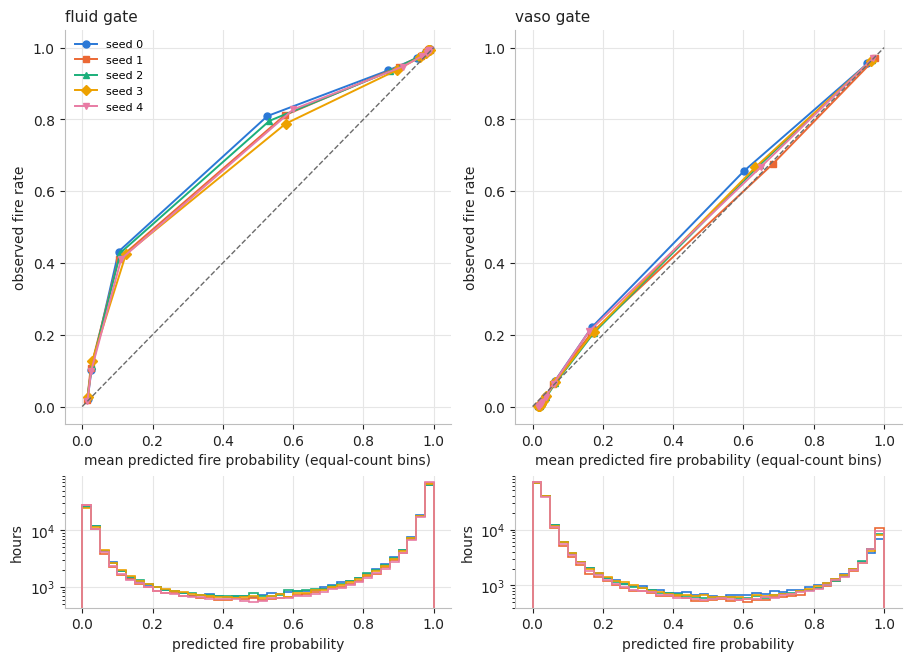

In [11]:
display(eval_bc.gate_summary(bc_models, procs).round(3))
eval_bc.plot_gate_reliability(bc_models, procs);

n_fired  z_mean   z_sd  frac_abs_z_gt3  frac_abs_z_gt10  std_min  \
seed drug                                                                      
0    fluid   126040   0.011  1.136           0.015              0.0    0.153   
     vaso     34149   0.108  1.106           0.013              0.0    0.286   
1    fluid   126040   0.024  1.193           0.019              0.0    0.136   
     vaso     34149   0.086  1.180           0.018              0.0    0.256   
2    fluid   126040  -0.031  1.171           0.017              0.0    0.146   
     vaso     34149   0.037  1.136           0.016              0.0    0.265   
3    fluid   126040  -0.024  1.180           0.018              0.0    0.164   
     vaso     34149   0.079  1.140           0.015              0.0    0.275   
4    fluid   126040  -0.021  1.192           0.020              0.0    0.153   
     vaso     34149   0.122  1.087           0.013              0.0    0.265   

            std_p50  std_p95  frac_at_upper_clamp  
seed drug                                          
0    fluid    0.409    0.584                  0.0  
     vaso     0.460    0.743                  0.0  
1    fluid    0.392    0.576                  0.0  
     vaso     0.416    0.740                  0.0  
2    fluid    0.400    0.573                  0.0  
     vaso     0.444    0.740                  0.0  
3    fluid    0.396    0.586                  0.0  
     vaso     0.450    0.740                  0.0  
4    fluid    0.392    0.574                  0.0  
     vaso     0.451    0.776                  0.0

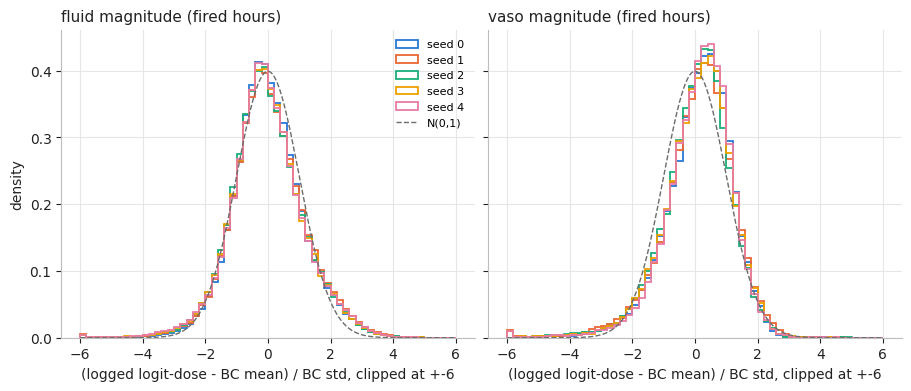

In [12]:
display(eval_bc.magnitude_summary(bc_models, procs).round(3))
eval_bc.plot_magnitude_z(bc_models, procs);

,seed,drug,severity_bin,n,obs_rate,mean_pred,obs_logit,bc_logit,z_mean,z_sd
0,0,fluid,0,11500,0.777,0.732,-0.564,-0.535,-0.085,1.109
1,0,fluid,1,20556,0.740,0.688,-0.636,-0.630,-0.013,1.054
10,0,vaso,0,11500,0.493,0.498,-0.304,-0.327,0.039,1.202
11,0,vaso,1,20556,0.375,0.353,-0.622,-0.632,-0.015,1.100
20,1,fluid,0,11500,0.777,0.722,-0.564,-0.585,0.044,1.140
21,1,fluid,1,20556,0.740,0.687,-0.636,-0.670,0.083,1.127
30,1,vaso,0,11500,0.493,0.485,-0.304,-0.385,0.172,1.246
31,1,vaso,1,20556,0.375,0.376,-0.622,-0.623,-0.035,1.241
40,2,fluid,0,11500,0.777,0.729,-0.564,-0.535,-0.078,1.104
41,2,fluid,1,20556,0.740,0.696,-0.636,-0.617,-0.059,1.104


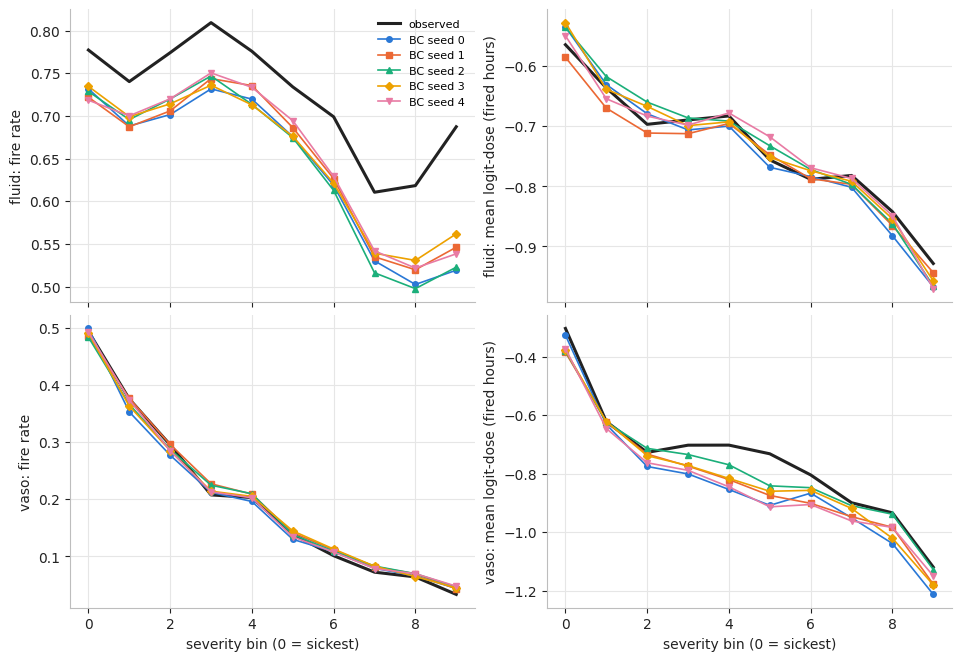

In [13]:
edges = D.severity_edges(D.health_score(train_ref)[0], n_bins=10)
sev_tbl = eval_bc.calibration_by_severity(bc_models, procs, edges)
eval_bc.plot_calibration_by_severity(sev_tbl);
display(sev_tbl[sev_tbl.severity_bin.isin([0, 1])].round(3))

In [14]:
for drug, df in eval_bc.cross_seed_agreement(bc_models, procs).items():
    print(drug); display(df.round(3))
display(eval_bc.fluid_gate_wis_impact(bc_models, procs).round(3))

fluid


,0,1,2,3,4
0,1.000,0.845,0.847,0.843,0.837
1,0.845,1.000,0.840,0.837,0.836
2,0.847,0.840,1.000,0.843,0.835
3,0.843,0.837,0.843,1.000,0.828
4,0.837,0.836,0.835,0.828,1.000


vaso


,0,1,2,3,4
0,1.000,0.834,0.818,0.827,0.817
1,0.834,1.000,0.818,0.827,0.816
2,0.818,0.818,1.000,0.815,0.799
3,0.827,0.827,0.815,1.000,0.803
4,0.817,0.816,0.799,0.803,1.000


,p_no_fluid_median,p_no_fluid_mean,p_no_vaso_median,p_no_vaso_mean,share_zero_fluid_median,share_zero_fluid_mean,share_zero_fluid_p90,n_stays
seed,,,,,,,,
0,0.976,0.895,0.974,0.932,0.061,0.166,0.517,1007
1,0.979,0.898,0.975,0.933,0.077,0.173,0.516,1007
2,0.975,0.890,0.974,0.931,0.065,0.170,0.521,1007
3,0.975,0.881,0.974,0.931,0.073,0.179,0.535,1007
4,0.978,0.895,0.975,0.934,0.072,0.174,0.517,1007


# standard deviation

In [16]:
import src.rl.evaluate_bc_actions as eval_bc_actions
import src.rl.clinician_baseline as clin_baseline   # your existing file, unchanged

store = D.DataStore(keep=("train", "val", "test"))   # re-create so test is available

out = eval_bc_actions.collect_bc_outputs(bc_models, store, split="test")   # computed once, reused below

  building processors for state seed 0, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_002923_675400_job4502770.pbs-7]  (splits: test

floor std = 0.1353 (exp(-2)), ceiling std = 2.7183 (exp(1))


,seed,drug,mean,sd,min,median,max,% at floor,% at ceiling
0,0,Fluid,0.4598,0.1410,0.1353,0.4489,1.1922,0.0109,0.0
1,0,Vaso,0.7895,0.2194,0.2748,0.8211,1.5199,0.0000,0.0
2,1,Fluid,0.4581,0.1516,0.1353,0.4413,1.2006,0.0350,0.0
3,1,Vaso,0.8249,0.2596,0.2479,0.8585,1.6825,0.0000,0.0
4,2,Fluid,0.4497,0.1347,0.1378,0.4414,1.2079,0.0000,0.0
5,2,Vaso,0.7871,0.2202,0.2680,0.8163,1.4944,0.0000,0.0
6,3,Fluid,0.4616,0.1519,0.1534,0.4413,1.1601,0.0000,0.0
7,3,Vaso,0.7745,0.2083,0.2790,0.8016,1.4883,0.0000,0.0
8,4,Fluid,0.4567,0.1485,0.1391,0.4364,1.3785,0.0000,0.0
9,4,Vaso,0.8154,0.2291,0.2698,0.8555,1.6540,0.0000,0.0


Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/std_distributions_by_seed_bc.png


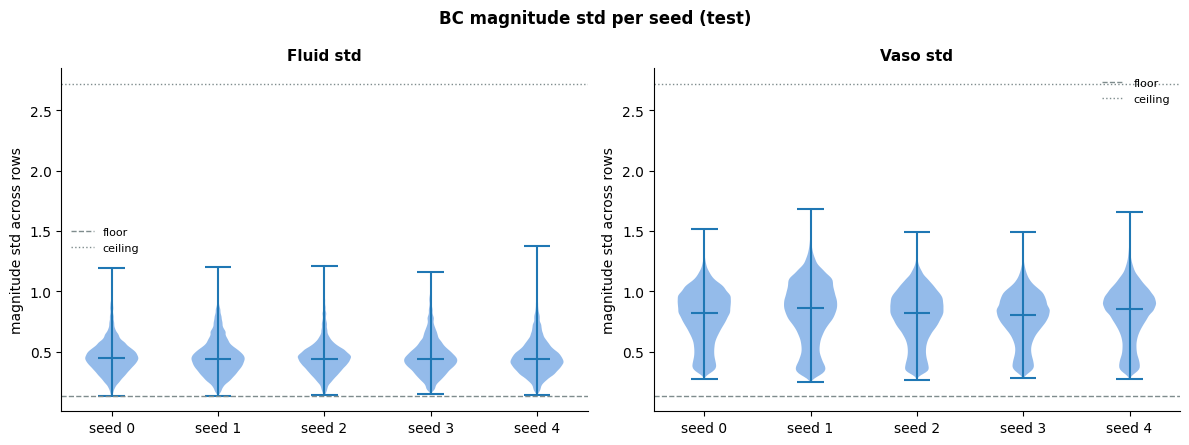

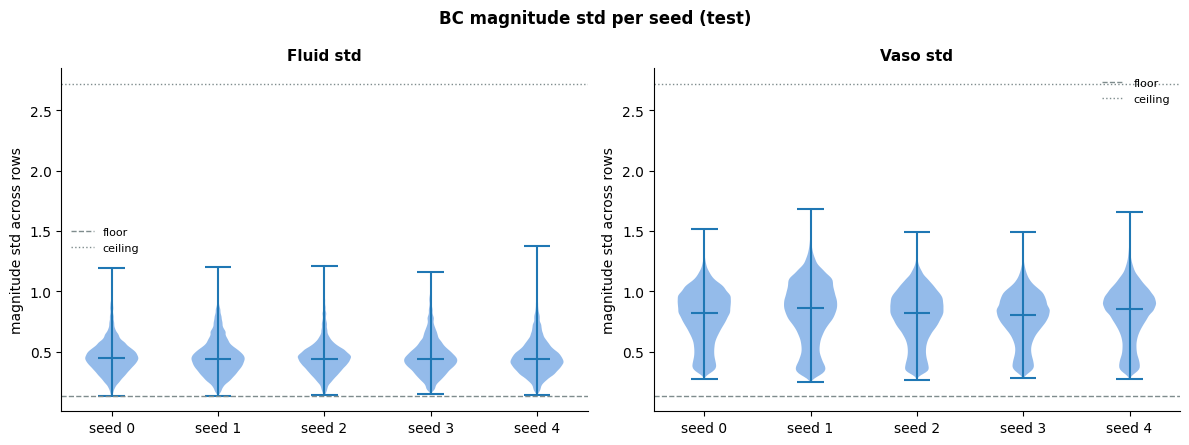

In [17]:
# std
display(eval_bc_actions.std_summary(out))
fig = eval_bc_actions.plot_std_distributions_by_seed(
    out, save_path=os.path.join(bc_dir, "std_distributions_by_seed_bc.png"))
fig

=== Clinician baseline (test) ===
  fluid: rate=71.3%, mean=0.2391, nonzero_mean=0.3353
  vaso: rate=19.3%, mean=0.0715, nonzero_mean=0.3700


,drug,seed,fire_rate,mean_dose,mean_nonzero_dose,exp_fire_rate
0,Fluid,clinician,0.7130,0.2391,0.3353,NaN
1,Fluid,0,0.6457,0.2209,0.3422,0.6337
2,Fluid,1,0.6504,0.2210,0.3398,0.6394
3,Fluid,2,0.6462,0.2222,0.3439,0.6341
4,Fluid,3,0.6517,0.2227,0.3417,0.6407
5,Fluid,4,0.6549,0.2247,0.3431,0.6440
6,Vaso,clinician,0.1932,0.0715,0.3700,NaN
7,Vaso,0,0.1672,0.0633,0.3788,0.1947
8,Vaso,1,0.1743,0.0655,0.3760,0.1989
9,Vaso,2,0.1699,0.0647,0.3805,0.1967


Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/stage3_actions_bc.png


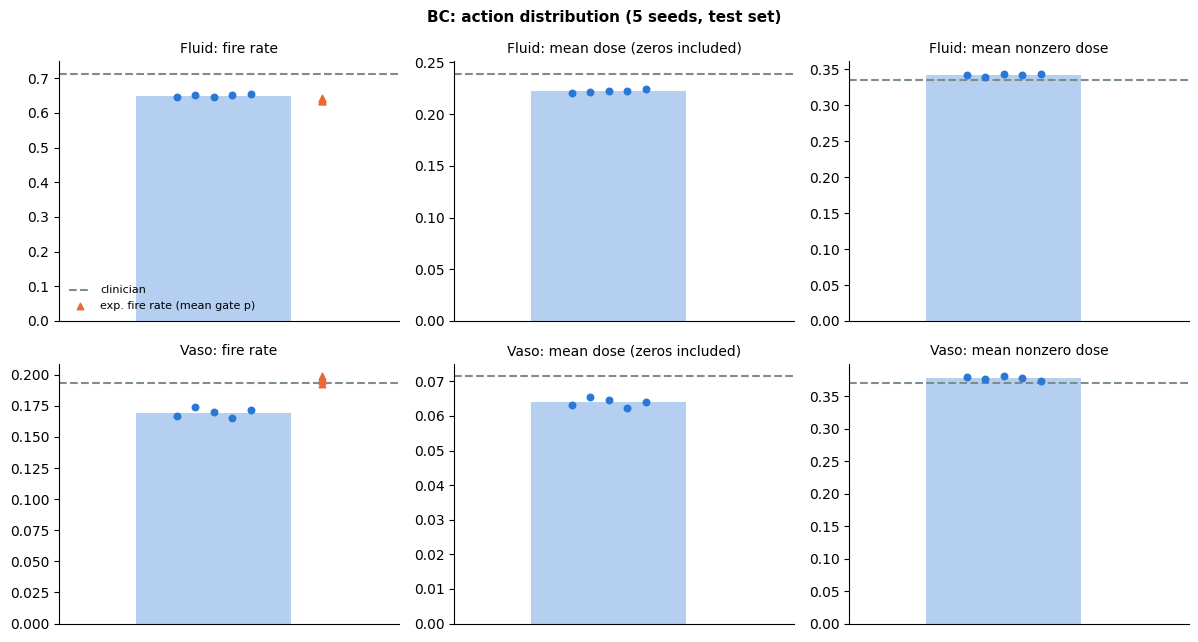

In [20]:
# summary
clin_test = clin_baseline.compute_clinician_baseline(out["clin"])
clin_baseline.print_clinician_baseline(clin_test, label="test")
display(eval_bc_actions.action_stats(out))
fig_bc = eval_bc_actions.plot_action_distribution(
    out, title="BC: action distribution (5 seeds, test set)",
    save_path=os.path.join(bc_dir, "stage3_actions_bc.png"))
fig_bc;

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/dose_histogram_fluid_bc.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/dose_histogram_vaso_bc.png


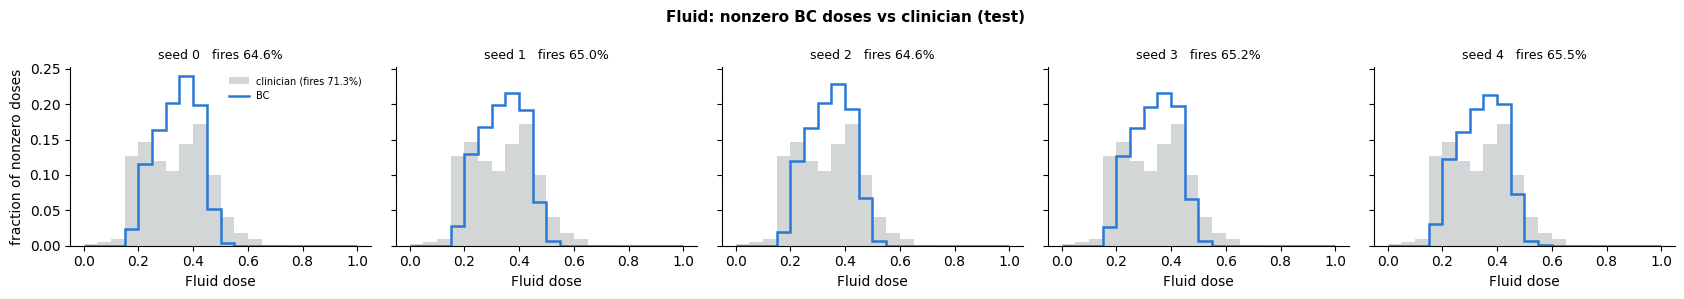

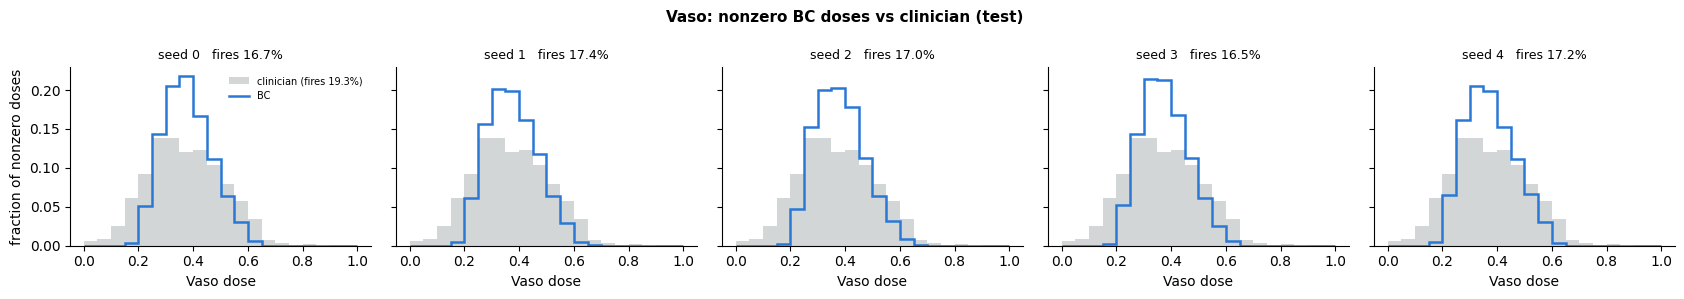

In [21]:
# dose histograms conditional on firing
fig_fluid = eval_bc_actions.plot_dose_histograms(out, dim=0, dim_name="Fluid",
    save_path=os.path.join(bc_dir, "dose_histogram_fluid_bc.png"))
fig_vaso = eval_bc_actions.plot_dose_histograms(out, dim=1, dim_name="Vaso",
    save_path=os.path.join(bc_dir, "dose_histogram_vaso_bc.png"))

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/fluid_at_clinician_zero_bc.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/mimic_iv/bc_with_logprobs/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/five_seeds/vaso_at_clinician_zero_bc.png


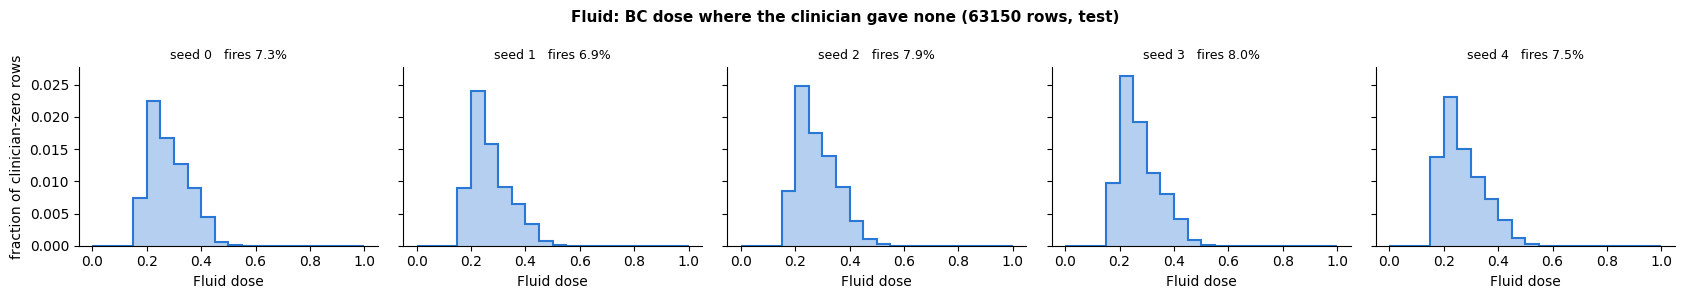

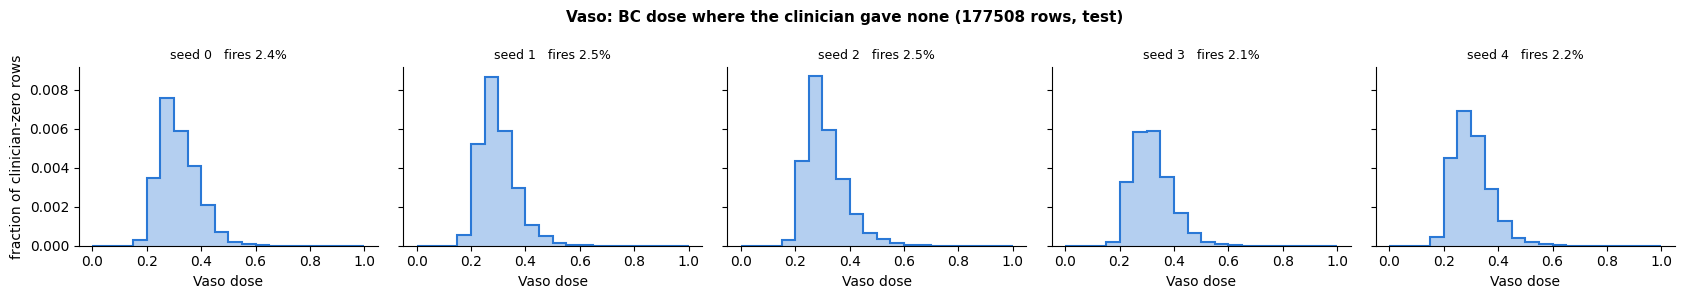

In [22]:
# does BC fire where the clinician withheld?
fig_fluid_zero = eval_bc_actions.plot_dose_histograms_at_clinician_zero(out, dim=0, dim_name="Fluid",
    save_path=os.path.join(bc_dir, "fluid_at_clinician_zero_bc.png"))
fig_vaso_zero = eval_bc_actions.plot_dose_histograms_at_clinician_zero(out, dim=1, dim_name="Vaso",
    save_path=os.path.join(bc_dir, "vaso_at_clinician_zero_bc.png"))